# ROG-Dialog v2 — explorer

Interactive look at ROG-Dialog v2: length / WPS distributions, **F1 topography** (how well does the matrix *perform* across the (duration × WPS) plane, not what label is there), and random listens across duration bands.

**Kernel:** select the `ssp` mamba env in VS Code.

Plot and loader code lives in `utils_rog_explorer.py` so this notebook stays scannable. Nothing is written to disk except the histogram PNG; nothing is retrained.

In [1]:
import json
import random
import sys
from pathlib import Path

from IPython.display import Audio, Markdown, display

ROOT = Path.cwd()
while ROOT.name and not (ROOT / 'data' / 'rog_dialog_v2_instance.jsonl').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Could not locate repo root with data/rog_dialog_v2_instance.jsonl')
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'scripts' / '6_sent_duration'))
import utils_rog_explorer as u
print('ROOT =', ROOT)

ROG_PATH   = ROOT / 'data' / 'rog_dialog_v2_instance.jsonl'
MATRIX_DIR = ROOT / 'misc' / 'run_results' / 'finetune_20261113_162724'

random.seed(42)

ROOT = /home/ivan/Posao_IJS/OpenRouter/Sentiment_Search


In [2]:
df = u.load_rog(ROG_PATH)
cell_preds = u.load_matrix_predictions(MATRIX_DIR)
df.head(3)

,instance_id,split,speaker,audio_path,text,sentiment,sentiment_3,sentiment_ord,duration,words,wps
0,ROG-Dialog_ROG-Dia-GSO-P0005_ROG-dialog-0007_0...,test,ROG-dialog-0007,data/processed_audio/ROG-Dialog-v2/ROG-Dia-GSO...,"Kaj zdaj,",mixedNegative,negative,1,0.578,2,3.460208
1,ROG-Dialog_ROG-Dia-GSO-P0005_ROG-dialog-0007_1...,test,ROG-dialog-0007,data/processed_audio/ROG-Dialog-v2/ROG-Dia-GSO...,si kupila karte za na Sardinijo?,mixedNegative,negative,1,1.884,6,3.184713
2,ROG-Dialog_ROG-Dia-GSO-P0005_ROG-dialog-0007_5...,test,ROG-dialog-0007,data/processed_audio/ROG-Dialog-v2/ROG-Dia-GSO...,"Ja, pa saj je čisto enostavno.",mixedNegative,negative,1,1.510,6,3.973510


## Distributions — duration, words, WPS

Also writes `docs/img/ROG-dia-v2_histograms.png` so the dataset-overview page stays in sync.

<2s: 10546 (77.2%)
2-5s: 2897
5-10s: 212
>10s: 3


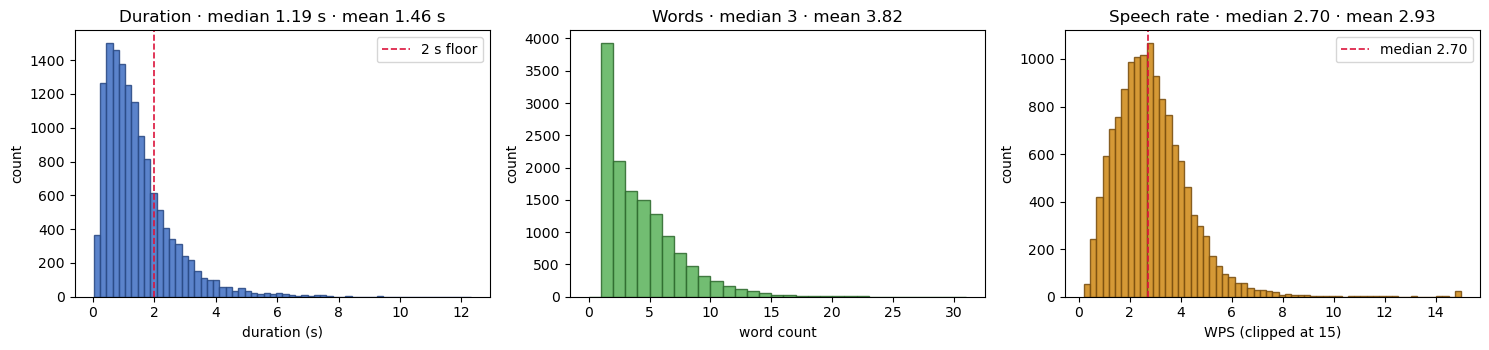

In [3]:
fig = u.plot_histograms(df, duration_floor=2.0)
out_png = ROOT / 'docs' / 'img' / 'ROG-dia-v2_histograms.png'
out_png.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_png, dpi=150, bbox_inches='tight')
print(f"<2s: {(df['duration'] < 2).sum()} ({100*(df['duration']<2).mean():.1f}%)")
print(f"2-5s: {((df['duration'] >= 2) & (df['duration'] < 5)).sum()}")
print(f"5-10s: {((df['duration'] >= 5) & (df['duration'] < 10)).sum()}")
print(f">10s: {(df['duration'] >= 10).sum()}")

## F1 topography — model performance across duration × WPS

**This is the main view.** Each cell shows the macro-F1 (3-cls) the matrix achieves on ROG test instances falling in that `(duration bin, WPS bin)`. Bins are quantiles on the scored instances (= the matrix's 2 s-filtered test split, n=434). The default below is the **best-cell envelope** — per bin, the single matrix cell with the highest F1 is picked, and its name is shown. This mirrors what the duration-signal study does.

The alternative — pick ONE fixed cell and plot its F1 across bins — is one cell below.

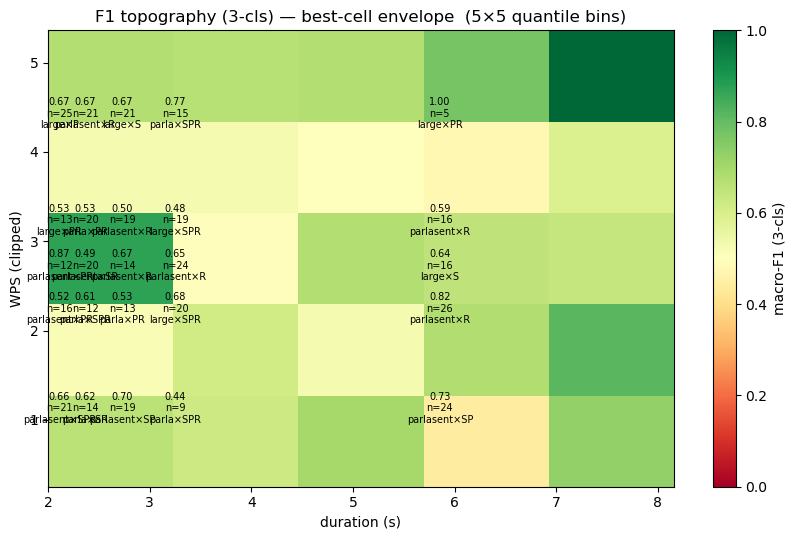

In [4]:
# Best-cell envelope — per bin, pick the matrix cell with the highest F1_3.
fig = u.plot_f1_topography_2d(df, cell_preds, cell_key=None, scheme='3',
                               n_dur_bins=5, n_wps_bins=5, wps_clip=10.0, mode='quantile')

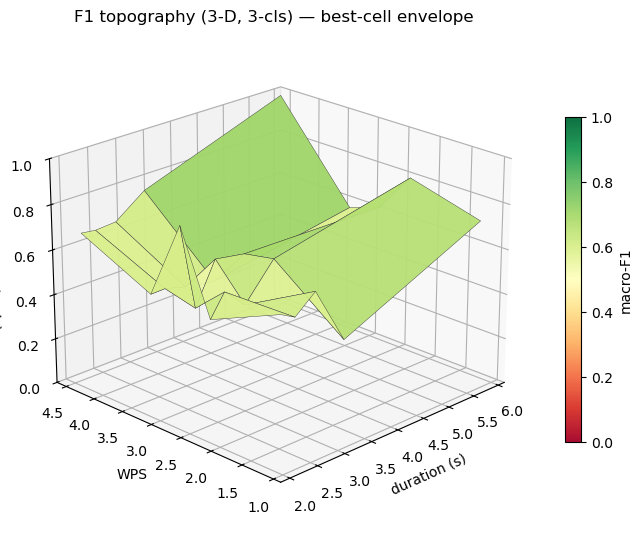

In [5]:
# 3-D surface of the same envelope.
fig = u.plot_f1_topography_3d(df, cell_preds, cell_key=None, scheme='3')

### F1 topography for a SINGLE cell

Change `cell_key` below to look at any specific (backbone, mixture). Cells in the current matrix follow `<backbone_short>__<mixture>` — e.g. `xlm-r-parla__SPR`, `xlm-r-parlasent__R`.

After the full-ROG rerun, `R_full / SR_full / PR_full / SPR_full` cells (and `rog_dia_full` test rows) will show up here too — just point `MATRIX_DIR` at the new matrix dir and re-run the loader cell.

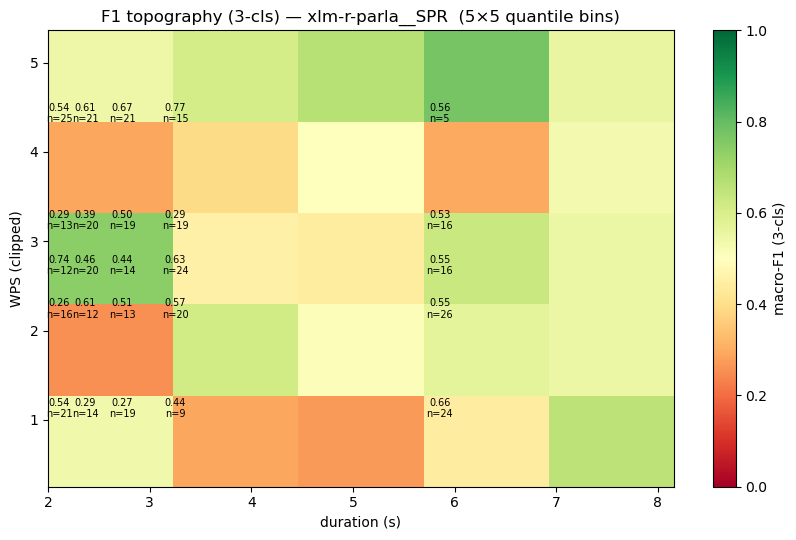

In [6]:
CELL = 'xlm-r-parla__SPR'   # change me
fig = u.plot_f1_topography_2d(df, cell_preds, cell_key=CELL, scheme='3')

## Context-envelope — F1 vs (context W × target feature)

Does giving Flash/Haiku more conversational context lift macro-F1 above the single-utterance baseline, and does the lift depend on target duration / target word count?

Baseline plane = iso (no-context) F1 averaged across bins, drawn as a transparent gray floor. The signal surface sits above it where context helped; stems from the raw grid points to the floor make the "pierce through" explicit. One plot per target feature (seconds / words) — audio equivalent is a stub until the audio context probe runs.

In [ ]:
ISO_BATCH  = ROOT / "runs" / "batch_FULL_20261111_115520"   # single-utterance Haiku/Flash
CTX_BATCHES = {
    0:  ROOT / "runs" / "batch_CTX_20261117_124601",
    10: ROOT / "runs" / "batch_CTXW10_20261117_140930",
    20: ROOT / "runs" / "batch_CTXW20_20261117_145015",
    30: ROOT / "runs" / "batch_CTXW30_20261117_152331",
    50: ROOT / "runs" / "batch_CTXW50_20261117_155630",
}

In [ ]:
# Flash 0-shot 3-cls envelope — the config with the highest numbers in the sweep.
sweep_flash = u.load_context_sweep(ISO_BATCH, CTX_BATCHES, model="flash", shot="0shot", scheme="3cls")
fig, (_Ws, _edges, _F1, _cnt, _iso) = u.plot_context_envelope_3d(
    sweep_flash, feature="duration", n_bins=5, title_suffix="Flash 0-shot 3-cls")
out = ROOT / "docs" / "img" / "ctx_envelope_flash_duration.png"
out.parent.mkdir(parents=True, exist_ok=True); fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"wrote {out}")

In [ ]:
fig, _ = u.plot_context_envelope_3d(
    sweep_flash, feature="words", n_bins=5, title_suffix="Flash 0-shot 3-cls")
out = ROOT / "docs" / "img" / "ctx_envelope_flash_words.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"wrote {out}")

In [ ]:
# Haiku 0-shot 3-cls — same view, cheaper model, confirms direction isn't Flash-specific.
sweep_haiku = u.load_context_sweep(ISO_BATCH, CTX_BATCHES, model="haiku", shot="0shot", scheme="3cls")
fig, _ = u.plot_context_envelope_3d(
    sweep_haiku, feature="duration", n_bins=5, title_suffix="Haiku 0-shot 3-cls")
out = ROOT / "docs" / "img" / "ctx_envelope_haiku_duration.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
print(f"wrote {out}")

**Audio equivalent — pending.** Same shape: x = context W, y = target duration (seconds), z = macro-F1. Blocked on the audio context probe (`scripts/3_probe_audio/`) being wired for ctx windows the way text now is.

## Listen to random utterances per duration band

Re-run a cell to draw a new sample. Model-performance grid only populates for instances in the 2 s-filtered ROG test split (n=434).

In [7]:
def listen(sub_df, n=5, seed=None):
    sampled = u.random_sample(sub_df, n=n, seed=seed)
    print(f"seed = {sampled.attrs.get('seed')}  · pool size = {len(sub_df)}")
    for i, (_, row) in enumerate(sampled.iterrows(), 1):
        display(Markdown(
            f"### {i}. `{row['instance_id']}`  —  **{row['sentiment']}**  (3-cls: {row['sentiment_3']})\n"
            f"- split: `{row['split']}`  · speaker: `{row['speaker']}`\n"
            f"- duration: **{row['duration']:.2f} s**  ·  words: **{row['words']}**  ·  WPS: **{row['wps']:.2f}**\n"
            f"- transcript: *{row['text']}*"
        ))
        wav = ROOT / row['audio_path'] if row['audio_path'] else None
        if wav is not None and wav.exists():
            display(Audio(str(wav)))
        else:
            display(Markdown(f'_audio missing at {wav}_'))
        display(Markdown(u.matrix_grid_md(row['instance_id'], cell_preds)))

### `< 2 s`

In [8]:
listen(df[df['duration'] < 2].reset_index(drop=True), n=5)

seed = 1867825  · pool size = 10546


### 1. `ROG-Dialog_ROG-Dia-GSO-P0022_ROG-dialog-0042_586.097_587.130`  —  **neutralPositive**  (3-cls: neutral)
- split: `test`  · speaker: `ROG-dialog-0042`
- duration: **1.03 s**  ·  words: **1**  ·  WPS: **0.97**
- transcript: *[glas]*

_not in 2 s-filtered test split — no matrix predictions_

### 2. `ROG-Dialog_ROG-Dia-GSO-P0019_ROG-dialog-0036_1410.001_1411.432`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0036`
- duration: **1.43 s**  ·  words: **2**  ·  WPS: **1.40**
- transcript: *naslednje leto.*

_not in 2 s-filtered test split — no matrix predictions_

### 3. `ROG-Dialog_ROG-Dia-GSO-P0021_ROG-dialog-0039_518.320_519.271`  —  **neutralNegative**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0039`
- duration: **0.95 s**  ·  words: **3**  ·  WPS: **3.15**
- transcript: *ven z mesta.*

_not in 2 s-filtered test split — no matrix predictions_

### 4. `ROG-Dialog_ROG-Dia-GSO-P0022_ROG-dialog-0042_65.377_66.371`  —  **neutralPositive**  (3-cls: neutral)
- split: `test`  · speaker: `ROG-dialog-0042`
- duration: **0.99 s**  ·  words: **5**  ·  WPS: **5.03**
- transcript: *A jih je bilo toliko?*

_not in 2 s-filtered test split — no matrix predictions_

### 5. `ROG-Dialog_ROG-Dia-GSO-P0005_ROG-dialog-0007_923.271_923.633`  —  **predominantlyPositive**  (3-cls: positive)
- split: `test`  · speaker: `ROG-dialog-0007`
- duration: **0.36 s**  ·  words: **1**  ·  WPS: **2.76**
- transcript: *Ja,*

_not in 2 s-filtered test split — no matrix predictions_

### `2 – 5 s`

In [9]:
listen(df[(df['duration'] >= 2) & (df['duration'] < 5)].reset_index(drop=True), n=5)

seed = 419610  · pool size = 2897


### 1. `ROG-Dialog_ROG-Dia-GSO-P0008_ROG-dialog-0014_273.809_277.816`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0014`
- duration: **4.01 s**  ·  words: **8**  ·  WPS: **2.00**
- transcript: *Zdaj zdaj, kot veš, sem postal Apple fan.*

_not in 2 s-filtered test split — no matrix predictions_

### 2. `ROG-Dialog_ROG-Dia-GSO-P0007_ROG-dialog-0011_403.151_405.886`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0011`
- duration: **2.74 s**  ·  words: **8**  ·  WPS: **2.93**
- transcript: *[glas] Miza bo pa zdajle trenutno ostala ista,*

_not in 2 s-filtered test split — no matrix predictions_

### 3. `ROG-Dialog_ROG-Dia-GSO-P0012_ROG-dialog-0021_575.933_578.487`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0021`
- duration: **2.55 s**  ·  words: **5**  ·  WPS: **1.96**
- transcript: *Če daš sladkor, prej kipne,*

_not in 2 s-filtered test split — no matrix predictions_

### 4. `ROG-Dialog_ROG-Dia-GSO-P0007_ROG-dialog-0012_1339.426_1342.858`  —  **mixedNegative**  (3-cls: negative)
- split: `train`  · speaker: `ROG-dialog-0012`
- duration: **3.43 s**  ·  words: **7**  ·  WPS: **2.04**
- transcript: *Naša tudi lahko rečem, da nekaj srednjega,*

_not in 2 s-filtered test split — no matrix predictions_

### 5. `ROG-Dialog_ROG-Dia-GSO-P0016_ROG-dialog-0029_304.711_308.506`  —  **neutralPositive**  (3-cls: neutral)
- split: `dev`  · speaker: `ROG-dialog-0029`
- duration: **3.79 s**  ·  words: **10**  ·  WPS: **2.64**
- transcript: *[glas] Ma eee papa naš je imel anka en voz.*

_not in 2 s-filtered test split — no matrix predictions_

### `5 – 10 s`

In [10]:
listen(df[(df['duration'] >= 5) & (df['duration'] < 10)].reset_index(drop=True), n=5)

seed = 4614226  · pool size = 212


### 1. `ROG-Dialog_ROG-Dia-GSO-P0019_ROG-dialog-0035_680.766_686.096`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0035`
- duration: **5.33 s**  ·  words: **13**  ·  WPS: **2.44**
- transcript: *Eem se ti zdi, da imaš Slovenijo že raziskano, kar ima za ponuditi,*

_not in 2 s-filtered test split — no matrix predictions_

### 2. `ROG-Dialog_ROG-Dia-GSO-P0009_ROG-dialog-0016_823.557_831.338`  —  **mixedPositive**  (3-cls: positive)
- split: `train`  · speaker: `ROG-dialog-0016`
- duration: **7.78 s**  ·  words: **8**  ·  WPS: **1.03**
- transcript: *Aaa aaa aha. Vidiš. Ja [smeh]. Ja ja.*

_not in 2 s-filtered test split — no matrix predictions_

### 3. `ROG-Dialog_ROG-Dia-GSO-P0016_ROG-dialog-0030_328.351_333.839`  —  **neutralPositive**  (3-cls: neutral)
- split: `dev`  · speaker: `ROG-dialog-0030`
- duration: **5.49 s**  ·  words: **16**  ·  WPS: **2.92**
- transcript: *Saj mi, mi smo, mi smo tudi takrat, ki je moj oče z vozom in osla.*

_not in 2 s-filtered test split — no matrix predictions_

### 4. `ROG-Dialog_ROG-Dia-GSO-P0012_ROG-dialog-0021_370.733_376.713`  —  **predominantlyNegative**  (3-cls: negative)
- split: `train`  · speaker: `ROG-dialog-0021`
- duration: **5.98 s**  ·  words: **11**  ·  WPS: **1.84**
- transcript: *s temi upokojenskimi plačami pa res si nena moreš tega privoščiti,*

_not in 2 s-filtered test split — no matrix predictions_

### 5. `ROG-Dialog_ROG-Dia-GSO-P0025_ROG-dialog-0048_1832.358_1838.095`  —  **neutralNegative**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0048`
- duration: **5.74 s**  ·  words: **13**  ·  WPS: **2.27**
- transcript: *Sem bil, sem bil glih, glih včeraj sem bil v v bivšem apartmaju*

_not in 2 s-filtered test split — no matrix predictions_

### `> 10 s`

In [11]:
listen(df[df['duration'] >= 10].reset_index(drop=True), n=5)

seed = 4108603  · pool size = 3


### 1. `ROG-Dialog_ROG-Dia-GSO-P0025_ROG-dialog-0048_1772.656_1782.889`  —  **mixedNegative**  (3-cls: negative)
- split: `train`  · speaker: `ROG-dialog-0048`
- duration: **10.23 s**  ·  words: **19**  ·  WPS: **1.86**
- transcript: *in na koncu, ko smo bili že vsi pač done, done, smo dobili pač štirikrat en() en() eno stvar.*

_not in 2 s-filtered test split — no matrix predictions_

### 2. `ROG-Dialog_ROG-Dia-GSO-P0019_ROG-dialog-0035_1723.674_1735.993`  —  **neutralPositive**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0035`
- duration: **12.32 s**  ·  words: **30**  ·  WPS: **2.44**
- transcript: *Kaj pa je mogoče neka izkušnja, k si jo pridobila na potovanjih, k te je v bistvu tako zaznamovala, da ti je v bistvu spremenila način, kako gledaš na življenje,*

_not in 2 s-filtered test split — no matrix predictions_

### 3. `ROG-Dialog_ROG-Dia-GSO-P0019_ROG-dialog-0035_1972.688_1984.442`  —  **neutralNegative**  (3-cls: neutral)
- split: `train`  · speaker: `ROG-dialog-0035`
- duration: **11.75 s**  ·  words: **28**  ·  WPS: **2.38**
- transcript: *mogoče kakšna država, k si trenutno izvedela zdaj o njej, da .. [glas] je nekaj tako narobe z njo, da ne bi stopila v državo ali pa destinacijo?*

_not in 2 s-filtered test split — no matrix predictions_